# Wall shapes — barbell, C, T, L, asymmetric

Real shear walls are rarely a plain rectangle. The `WallSection` models a wall as a **web** plus up to **two boundary elements (BEs)** at the ends of the wall length, and each BE has two knobs that, combined, reproduce the common shapes:

* **`be_thickness`** — the BE's dimension *across* the wall thickness. Set it equal to `tw` for a plain end zone, a bit larger for an **enlarged boundary element (cabezal / barbell)**, or much larger for a **flange**.
* **`be_align` / `be_*_align`** (`'center'|'left'|'right'`) — offsets the (wider) BE to one face, turning a symmetric barbell into an **asymmetric C / L / T**.

| Shape | How it is built |
|-------|-----------------|
| Rectangular | no BE (`be_*_length = 0`) |
| Barbell / **cabezales grandes** | both ends, `be_thickness > tw`, centered |
| **C-shape** | both ends widened and flushed to the **same** face (`be_align='left'`) |
| **T / flanged** | one end with a wide, centered flange (`be_top_thickness >> tw`) |
| **L-shape** | one end with a wide flange flushed to one face |
| Asymmetric | each end a different thickness/alignment |

All of these flow through the **same** PMM strain-compatibility kernel, so the interaction capacity reflects the true geometry, and each BE is still detailed as a real `Column`.

> **What this does *not* model:** an arbitrary I/T/C polygon editor, a flange running perpendicular at mid-web, multiple webs, or flange reinforcement distributed independently of the BE rectangle. A 'flange' here is a wide **end** boundary element — which is exactly the ACI §18.10.6 boundary-element idealization.

## Setup + a factory that only varies the BE geometry

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
import numpy as np, matplotlib.pyplot as plt
from design.common.materials import Concrete, Steel
from design.walls.wall import Wall

concrete = Concrete(fc=35.0)
steel = Steel(fy=420.0)

def make(**be):
    base = dict(lw=4000, tw=300, hw=15000, lu=3000,
        concrete=concrete, steel=steel, n_y_web=10, db_web=12, cover=25,
        n_x_be=3, n_y_be=4, db_be=25, db_stirrup=10,
        seismic=True, rho_t=0.0025, rho_l=0.0025)
    base.update(be)
    return Wall.rectangular(**base).run()

## Build the six shapes

Only the boundary-element arguments change — the web (`lw=4000`, `tw=300`) is identical everywhere.

In [2]:
shapes = {
    "Rectangular":            dict(be_top_length=0,   be_bot_length=0),
    "Barbell (cabezales)":    dict(be_top_length=700, be_bot_length=700,
                                   be_top_thickness=700, be_bot_thickness=700),
    "C-shape":                dict(be_top_length=700, be_bot_length=700,
                                   be_top_thickness=700, be_bot_thickness=700,
                                   be_align="left"),
    "T / flanged":            dict(be_top_length=400, be_bot_length=0,
                                   be_top_thickness=1600),
    "L-shape":                dict(be_top_length=400, be_bot_length=0,
                                   be_top_thickness=1600, be_top_align="left"),
    "Asymmetric":             dict(be_top_length=700, be_bot_length=700,
                                   be_top_thickness=900, be_bot_thickness=450,
                                   be_top_align="right", be_bot_align="left"),
}
walls = {name: make(**kw) for name, kw in shapes.items()}
print(f"{len(walls)} walls built (web is identical; only the BEs differ)")

6 walls built (web is identical; only the BEs differ)


## Plot every cross-section

`wall.plot.section` draws the web + BE polygons and the rebar. Note how the **x-extent** (across the thickness) changes with the BE thickness and alignment, while the wall length stays 4 m.

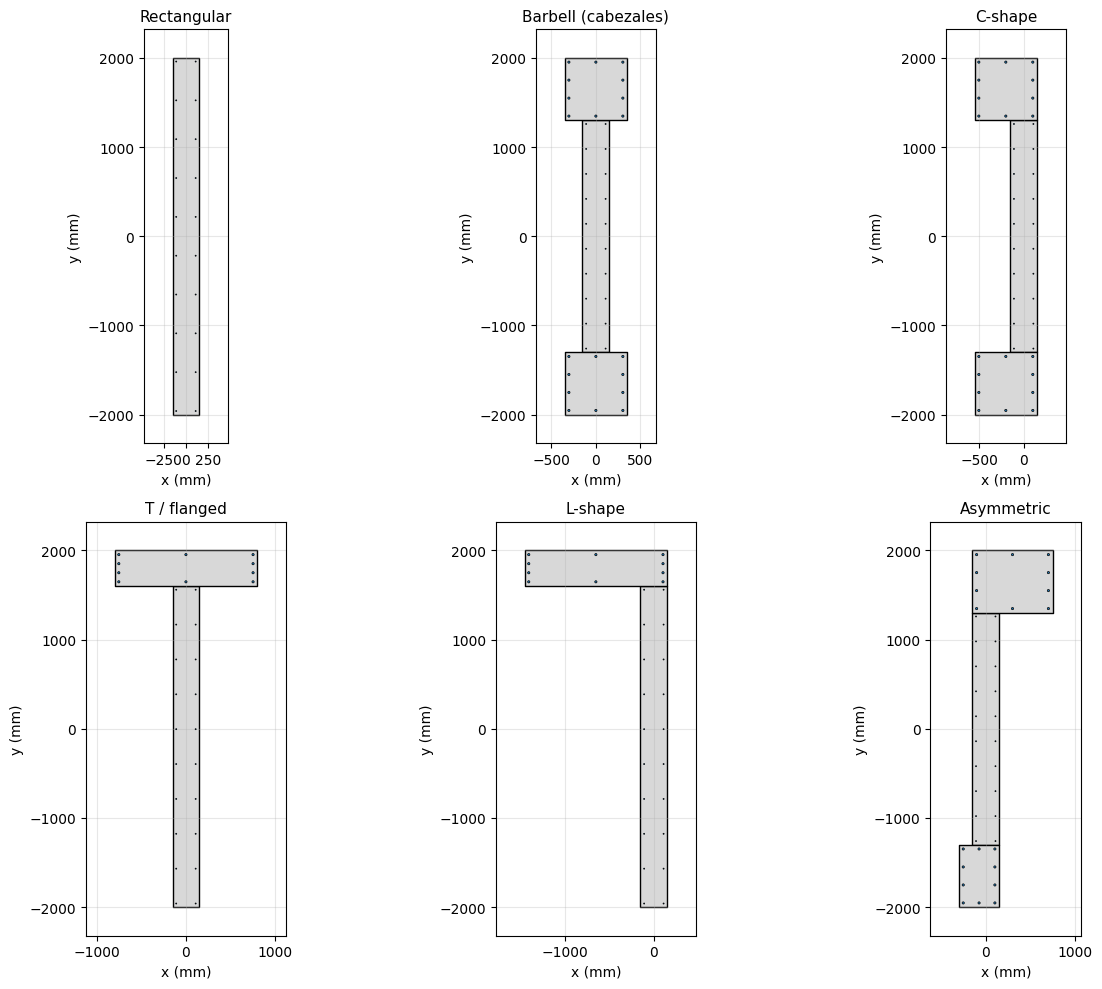

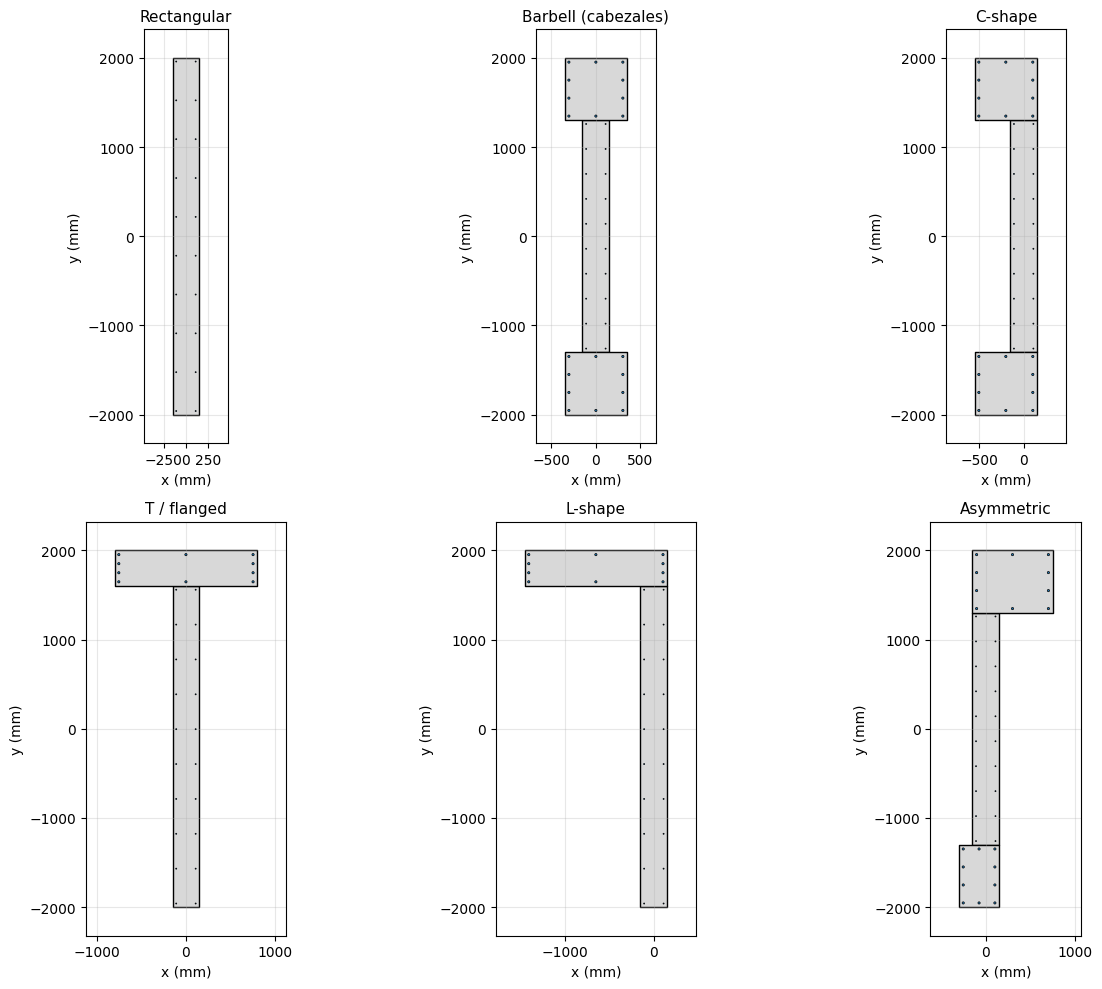

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 10))
for ax, (name, w) in zip(axes.ravel(), walls.items()):
    w.plot.section(ax=ax)
    ax.set_title(name, fontsize=11)
fig.tight_layout(); fig

## Compare the geometry & in-plane flexural capacity

The enlarged boundary elements add area exactly where the lever arm is largest, so the in-plane `max φ·Mn` rises sharply from the plain rectangle to the flanged shapes.

In [4]:
rows = []
for name, w in walls.items():
    bb = w.section.bounding_box()
    rows.append((name, w.section.gross_area(), bb[2]-bb[0],
                 float(max(w.surface[0.0].phi_Mn)), w.phi_Vn))
print(f"{'shape':22}{'Ag (mm2)':>12}{'x-extent':>10}{'maxφMn(kNm)':>14}{'φVn(kN)':>10}")
for n, ag, xe, mn, vn in rows:
    print(f"{n:22}{ag:>12.0f}{xe:>10.0f}{mn:>14.0f}{vn:>10.0f}")

shape                     Ag (mm2)  x-extent   maxφMn(kNm)   φVn(kN)
Rectangular                1200000       300         13919      1850
Barbell (cabezales)        1760000       700         31372      1850
C-shape                    1760000       700         31372      1850
T / flanged                1720000      1600         41803      1850
L-shape                    1720000      1600         41803      1850
Asymmetric                 1725000      1050         37557      1850


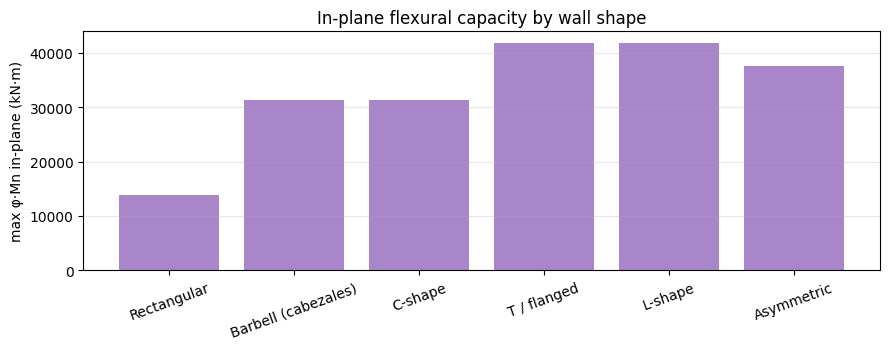

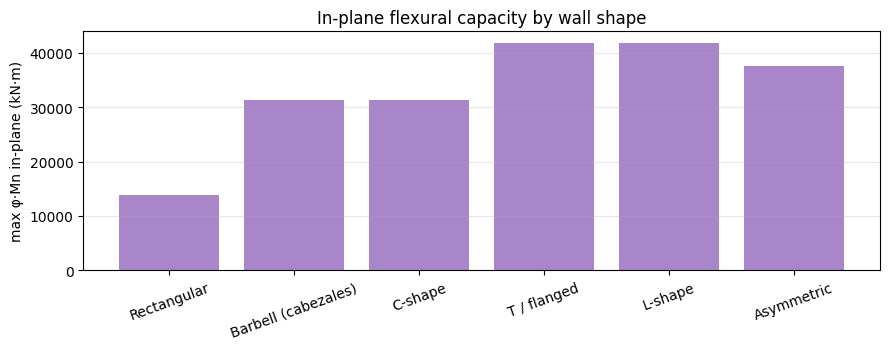

In [5]:
names = [r[0] for r in rows]
mn = [r[3] for r in rows]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(names, mn, color="tab:purple", alpha=0.8)
ax.set_ylabel("max φ·Mn in-plane (kN·m)")
ax.set_title("In-plane flexural capacity by wall shape")
ax.tick_params(axis="x", rotation=20); ax.grid(alpha=.3, axis="y")
fig.tight_layout(); fig

## Each boundary element is still a `Column`

No matter the shape, the BE is extracted as a real `Column` (`be_top_as_rectangular()` → `b × h` = thickness × length) and detailed with the column confinement engine.

In [6]:
for name in ["Barbell (cabezales)", "T / flanged", "Asymmetric"]:
    w = walls[name]
    be = w.be_top
    print(f"{name:22} be_top = Column {be.section.b:.0f}×{be.section.h:.0f} mm   "
          f"Po = {be.run().Po:.0f} kN")

Barbell (cabezales)    be_top = Column 700×700 mm   Po = 16493 kN
T / flanged            be_top = Column 1600×400 mm   Po = 20956 kN


Asymmetric             be_top = Column 900×700 mm   Po = 20658 kN


---
### Summary

* **Yes**, the toolkit builds barbell / cabezales, C, T, L and fully asymmetric walls — all by varying the two BE knobs (`be_thickness`, `be_align`).
* Capacity scales with the shape because every polygon goes through the same PMM kernel.
* Every BE is a `Column`, so confinement, `Ash`, hoops and `Mpr` come from the column engine for free.
* The one thing to keep in mind: a 'flange' is modelled as a **wide end boundary element**, the ACI §18.10.6 idealization — not an arbitrary cruciform/multi-web polygon.